# 02 — Envelope Extraction

Phase 1, step 4: pull the amplitude envelope out of each band.

The envelope is the slowly-varying amplitude that rides on top of a band's
fast oscillations — it's the only thing a channel vocoder actually transmits
per channel (the carrier supplies the fine timing/pitch structure instead).
Two equivalent ways to get it:

1. **Rectify + lowpass**: `abs(signal)` then a lowpass filter (around 400 Hz cutoff)
   to smooth out the rectified ripple.
2. **Hilbert transform**: `scipy.signal.hilbert` gives the analytic signal;
   its magnitude is the envelope directly.

This notebook rebuilds the filterbank from `01_filterbank.ipynb` (same
functions, same N=8 starting point), extracts both envelope versions per
band, and compares them — both visually and by ear — before picking one to
carry forward.

In [9]:
import numpy as np
import soundfile as sf
from scipy import signal
import matplotlib.pyplot as plt
from IPython.display import Audio, display

TARGET_SR = 16000  # Nyquist = 8 kHz, comfortably above our 7 kHz band ceiling

## Rebuild the filterbank setup from 01

Same loading, resampling, and filterbank-design functions as the previous
notebook — not re-explained here, see `01_filterbank.ipynb` for the
reasoning. This just gets us back to "N bands split out" so we have
something to extract envelopes from.

In [10]:
def load_raw(path):
    audio, native_sr = sf.read(path)
    if audio.ndim > 1:
        audio = audio.mean(axis=1)
    return audio.astype(np.float32), native_sr


def resample_to(audio, native_sr, target_sr):
    if native_sr == target_sr:
        return audio
    n_samples = int(len(audio) * target_sr / native_sr)
    return signal.resample(audio, n_samples).astype(np.float32)


def design_filterbank(n_channels, sr, f_min=200, f_max=7000, order=4):
    """Return (sos_list, edges, centers) for N log-spaced Butterworth bandpass filters."""
    edges = np.logspace(np.log10(f_min), np.log10(f_max), n_channels + 1)
    centers = np.sqrt(edges[:-1] * edges[1:])  # geometric mean = center freq per band

    nyquist = sr / 2
    sos_list = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        sos = signal.butter(order, [lo / nyquist, hi / nyquist], btype="bandpass", output="sos")
        sos_list.append(sos)

    return sos_list, edges, centers


def split_into_bands(audio, sos_list):
    return [signal.sosfiltfilt(sos, audio) for sos in sos_list]


speech_raw, speech_native_sr = load_raw("../samples/speech.wav")
music_raw, music_native_sr = load_raw("../samples/music.wav")

speech = resample_to(speech_raw, speech_native_sr, TARGET_SR)
music = resample_to(music_raw, music_native_sr, TARGET_SR)
sr = TARGET_SR

N_CHANNELS = 8
filterbank, edges, centers = design_filterbank(N_CHANNELS, sr)
speech_bands = split_into_bands(speech, filterbank)
music_bands = split_into_bands(music, filterbank)

print(f"{N_CHANNELS} bands ready, {len(speech_bands[0])} samples each @ {sr} Hz")

8 bands ready, 41920 samples each @ 16000 Hz


## Method 1: rectify + lowpass

Full-wave rectify (`abs`) turns the oscillating band signal into an
all-positive ripple at twice the band's frequency content; a lowpass at
around 400 Hz smooths that ripple down to the slow amplitude trend. 400 Hz is
comfortably above typical syllable-rate modulation (roughly 2-16 Hz) but well
below any band's carrier frequency, so it separates "envelope" from
"fine structure" cleanly.

In [11]:
def envelope_rectify_lowpass(band, sr, cutoff=400, order=4):
    rectified = np.abs(band)
    nyquist = sr / 2
    sos = signal.butter(order, cutoff / nyquist, btype="lowpass", output="sos")
    return signal.sosfiltfilt(sos, rectified)


ENV_CUTOFF = 400
speech_env_rect = [envelope_rectify_lowpass(b, sr, ENV_CUTOFF) for b in speech_bands]
music_env_rect = [envelope_rectify_lowpass(b, sr, ENV_CUTOFF) for b in music_bands]

print(f"{len(speech_env_rect)} envelopes extracted (rectify+lowpass, cutoff={ENV_CUTOFF} Hz)")

8 envelopes extracted (rectify+lowpass, cutoff=400 Hz)


## Method 2: Hilbert transform

`scipy.signal.hilbert` returns the analytic signal (band signal + its
quadrature component as the imaginary part); `np.abs` of that is the
envelope directly, with no cutoff parameter to pick.

In [12]:
def envelope_hilbert(band):
    return np.abs(signal.hilbert(band))


speech_env_hilbert = [envelope_hilbert(b) for b in speech_bands]
music_env_hilbert = [envelope_hilbert(b) for b in music_bands]

print(f"{len(speech_env_hilbert)} envelopes extracted (Hilbert)")

8 envelopes extracted (Hilbert)


## Compare the two methods

Plot both envelopes over the raw band waveform for the lowest and highest
speech bands. They should trace the same broad amplitude contour — the
rectify+lowpass version will look slightly smoother/more delayed (it's an
actual lowpass filter), while the Hilbert version tracks faster amplitude
changes a bit more tightly.

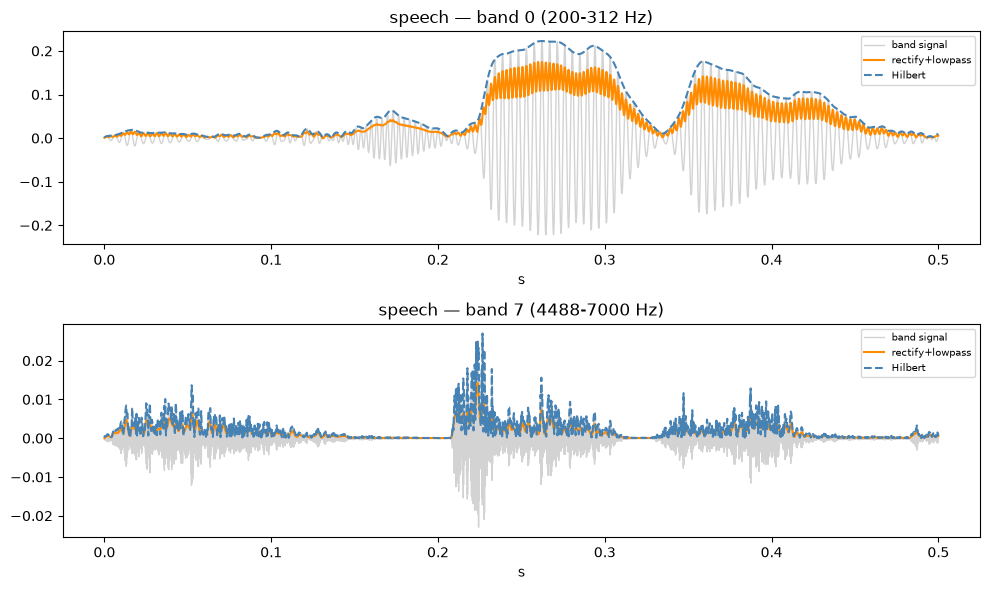

In [13]:
def plot_envelope_compare(band, env_rect, env_hilbert, sr, title, ax, window_s=0.5):
    n = int(window_s * sr)
    t = np.arange(n) / sr

    ax.plot(t, band[:n], color="lightgray", linewidth=1, label="band signal")
    ax.plot(t, env_rect[:n], color="darkorange", linewidth=1.5, label="rectify+lowpass")
    ax.plot(t, env_hilbert[:n], color="steelblue", linewidth=1.5, linestyle="--", label="Hilbert")
    ax.set_title(title)
    ax.set_xlabel("s")
    ax.legend(fontsize=7)


fig, axes = plt.subplots(2, 1, figsize=(10, 6))
plot_envelope_compare(
    speech_bands[0], speech_env_rect[0], speech_env_hilbert[0], sr,
    f"speech — band 0 ({edges[0]:.0f}-{edges[1]:.0f} Hz)", axes[0],
)
plot_envelope_compare(
    speech_bands[-1], speech_env_rect[-1], speech_env_hilbert[-1], sr,
    f"speech — band {N_CHANNELS - 1} ({edges[-2]:.0f}-{edges[-1]:.0f} Hz)", axes[1],
)
plt.tight_layout()
plt.show()

## Sanity check by ear

The envelope itself is near-DC (it's the thing that's *left* after
lowpassing at 400 Hz), so playing it back directly doesn't sound like
much — but it should still audibly track the loudness contour of the
original band: louder during speech, near-silent in gaps. Compare the
band signal to its rectify+lowpass envelope for the same band.

In [14]:
print("speech — band 0, original:")
display(Audio(speech_bands[0], rate=sr))
print("speech — band 0, rectify+lowpass envelope:")
display(Audio(speech_env_rect[0], rate=sr))

speech — band 0, original:


speech — band 0, rectify+lowpass envelope:


## Picking a method

Both are correct and the plots above should look nearly identical. Going
forward, this project uses **rectify + lowpass**: it's the simpler
operation to port to Swift — `vDSP_vabs` followed by a `vDSP_biquad`
lowpass maps directly onto it, whereas Hilbert would need an FFT-based
analytic-signal approach on the Swift side for no real accuracy gain here.
Wrap it as `extract_envelope` / `extract_envelopes` for the next notebook.

In [15]:
def extract_envelope(band, sr, cutoff=400, order=4):
    return envelope_rectify_lowpass(band, sr, cutoff, order)


def extract_envelopes(bands, sr, cutoff=400, order=4):
    return [extract_envelope(b, sr, cutoff, order) for b in bands]


speech_envelopes = extract_envelopes(speech_bands, sr, ENV_CUTOFF)
music_envelopes = extract_envelopes(music_bands, sr, ENV_CUTOFF)

print(f"speech: {len(speech_envelopes)} envelopes, music: {len(music_envelopes)} envelopes")

speech: 8 envelopes, music: 8 envelopes
